<a href="https://colab.research.google.com/github/sayandeepr8/Lab1/blob/main/Lab6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn imbalanced-learn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report
)

from imblearn.over_sampling import RandomOverSampler

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
uploaded = files.upload()

file_name = list(uploaded.keys())[0]

df = pd.read_csv(file_name)

print("Dataset uploaded successfully!")

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Saving stroke_processed_5k.csv to stroke_processed_5k.csv
Dataset uploaded successfully!

First 5 Rows:


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,1,1.051434,0,1,1,2,1,2.706375,1.005086,1,1
1,0,0.786070,0,0,1,3,0,2.121559,-0.098981,2,1
2,1,1.626390,0,1,1,2,0,-0.005028,0.472536,2,1
3,0,0.255342,0,0,1,2,1,1.437358,0.719327,3,1
4,0,1.582163,1,0,1,3,0,1.501184,-0.631531,2,1



Dataset Shape:
(5110, 11)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   gender             5110 non-null   int64  
 1   age                5110 non-null   float64
 2   hypertension       5110 non-null   int64  
 3   heart_disease      5110 non-null   int64  
 4   ever_married       5110 non-null   int64  
 5   work_type          5110 non-null   int64  
 6   Residence_type     5110 non-null   int64  
 7   avg_glucose_level  5110 non-null   float64
 8   bmi                5110 non-null   float64
 9   smoking_status     5110 non-null   int64  
 10  stroke             5110 non-null   int64  
dtypes: float64(3), int64(8)
memory usage: 439.3 KB

Missing Values:
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_typ

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
count,5110.000000,5.110000e+03,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,5.110000e+03,5.110000e+03,5110.000000,5110.000000
mean,0.414286,4.449583e-17,0.097456,0.054012,0.656164,2.167710,0.508023,1.168015e-16,-3.893385e-17,1.376908,0.048728
std,0.493044,1.000098e+00,0.296607,0.226063,0.475034,1.090293,0.499985,1.000098e+00,1.000098e+00,1.071534,0.215320
min,0.000000,-1.908261e+00,0.000000,0.000000,0.000000,0.000000,0.000000,-1.126958e+00,-2.411027e+00,0.000000,0.000000
25%,0.000000,-8.061152e-01,0.000000,0.000000,0.000000,2.000000,0.000000,-6.383223e-01,-6.575089e-01,0.000000,0.000000
50%,0.000000,7.843218e-02,0.000000,0.000000,1.000000,2.000000,1.000000,-3.149945e-01,-9.898092e-02,2.000000,0.000000
75%,1.000000,7.860701e-01,0.000000,0.000000,1.000000,3.000000,1.000000,1.754080e-01,5.115031e-01,2.000000,0.000000
max,2.000000,1.714845e+00,1.000000,1.000000,1.000000,4.000000,1.000000,3.657145e+00,8.928390e+00,3.000000,1.000000


Stroke Distribution:
stroke
0    4861
1     249
Name: count, dtype: int64


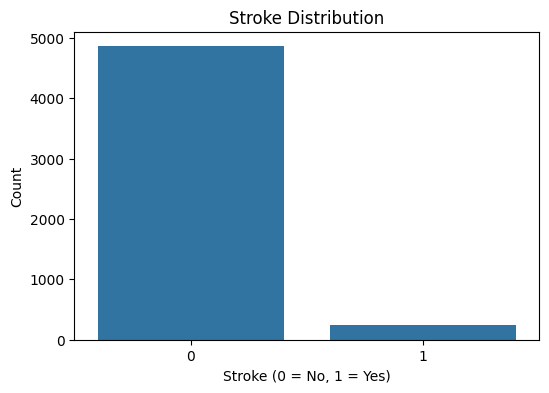

In [4]:
# Statistical summary
display(df.describe())

# Check stroke distribution
print("Stroke Distribution:")
print(df['stroke'].value_counts())

# Visualize stroke distribution
plt.figure(figsize=(6,4))

sns.countplot(data=df, x='stroke')

plt.title("Stroke Distribution")
plt.xlabel("Stroke (0 = No, 1 = Yes)")
plt.ylabel("Count")

plt.show()

In [5]:
# Remove ID column if available
if 'id' in df.columns:
    df = df.drop('id', axis=1)

# Separate input features and target
X = df.drop('stroke', axis=1)
y = df['stroke'].astype(int)

# Identify numerical columns
numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

# Identify categorical columns
categorical_features = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)
])

print("\nPreprocessing completed!")

Numerical Features:
['gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status']

Categorical Features:
[]

Preprocessing completed!


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

print("\nTraining Distribution:")
print(y_train.value_counts())

print("\nTesting Distribution:")
print(y_test.value_counts())

Training Shape: (4088, 10)
Testing Shape: (1022, 10)

Training Distribution:
stroke
0    3889
1     199
Name: count, dtype: int64

Testing Distribution:
stroke
0    972
1     50
Name: count, dtype: int64


In [7]:
# Fit preprocessing on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data
X_test_processed = preprocessor.transform(X_test)

# Balance training dataset
ros = RandomOverSampler(random_state=42)

X_train_balanced, y_train_balanced = ros.fit_resample(
    X_train_processed,
    y_train
)

print("Before balancing:")
print(y_train.value_counts())

print("\nAfter balancing:")
print(pd.Series(y_train_balanced).value_counts())

print("\nData preparation completed!")

Before balancing:
stroke
0    3889
1     199
Name: count, dtype: int64

After balancing:
stroke
0    3889
1    3889
Name: count, dtype: int64

Data preparation completed!


In [8]:
models = {

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=10,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    ),

    "SVM": SVC(
        kernel='rbf',
        probability=True,
        random_state=42
    ),

    "ANN": MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation='relu',
        solver='adam',
        max_iter=300,
        early_stopping=True,
        random_state=42
    )
}

print("All five models are ready!")

All five models are ready!


In [9]:
results = []

trained_models = {}

predictions = {}

probabilities = {}

for name, model in models.items():

    print("\nTraining:", name)

    # Train model
    model.fit(X_train_balanced, y_train_balanced)

    # Predict test data
    y_pred = model.predict(X_test_processed)

    # Get prediction probabilities
    y_prob = model.predict_proba(X_test_processed)[:, 1]

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    auc = roc_auc_score(y_test, y_prob)

    # Store results
    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'AUC-ROC': auc
    })

    trained_models[name] = model
    predictions[name] = y_pred
    probabilities[name] = y_prob

    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1-Score:", round(f1, 4))
    print("AUC-ROC:", round(auc, 4))

print("\nAll models trained and evaluated!")


Training: Logistic Regression
Accuracy: 0.7456
Precision: 0.1379
Recall: 0.8
F1-Score: 0.2353
AUC-ROC: 0.8391

Training: Decision Tree
Accuracy: 0.8346
Precision: 0.1437
Recall: 0.48
F1-Score: 0.2212
AUC-ROC: 0.6739

Training: Random Forest
Accuracy: 0.9354
Precision: 0.1364
Recall: 0.06
F1-Score: 0.0833
AUC-ROC: 0.8013

Training: SVM
Accuracy: 0.7466
Precision: 0.1144
Recall: 0.62
F1-Score: 0.1931
AUC-ROC: 0.7742

Training: ANN
Accuracy: 0.8669
Precision: 0.1417
Recall: 0.34
F1-Score: 0.2
AUC-ROC: 0.7683

All models trained and evaluated!


In [10]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='F1-Score',
    ascending=False
).reset_index(drop=True)

print("PERFORMANCE COMPARISON OF FIVE MODELS")

display(
    results_df.style.format({
        'Accuracy': '{:.4f}',
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F1-Score': '{:.4f}',
        'AUC-ROC': '{:.4f}'
    }).background_gradient(cmap='YlGn')
)

PERFORMANCE COMPARISON OF FIVE MODELS


,Model,Accuracy,Precision,Recall,F1-Score,AUC-ROC
0,Logistic Regression,0.7456,0.1379,0.8000,0.2353,0.8391
1,Decision Tree,0.8346,0.1437,0.4800,0.2212,0.6739
2,ANN,0.8669,0.1417,0.3400,0.2000,0.7683
3,SVM,0.7466,0.1144,0.6200,0.1931,0.7742
4,Random Forest,0.9354,0.1364,0.0600,0.0833,0.8013


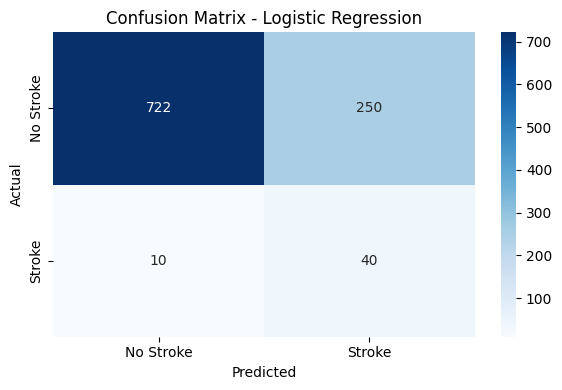

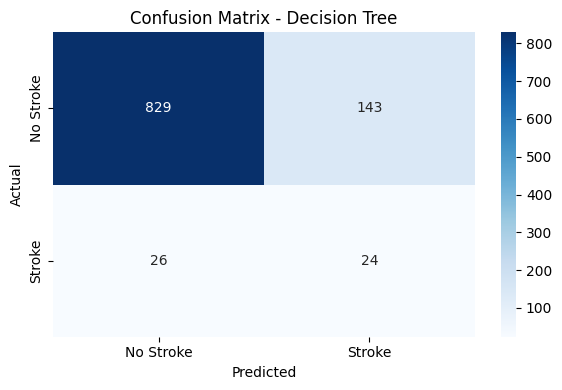

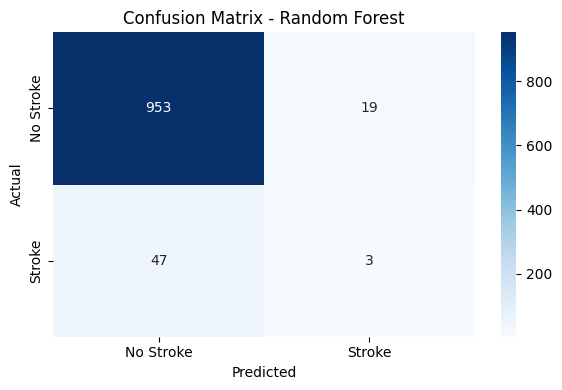

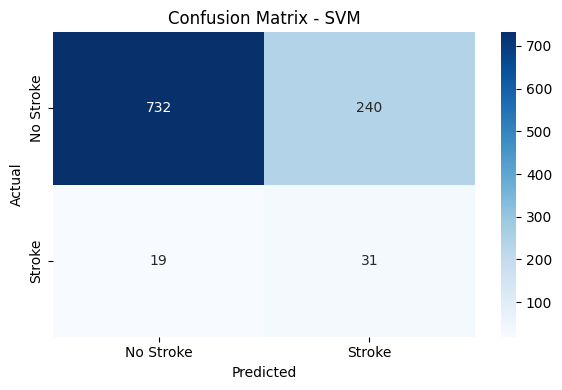

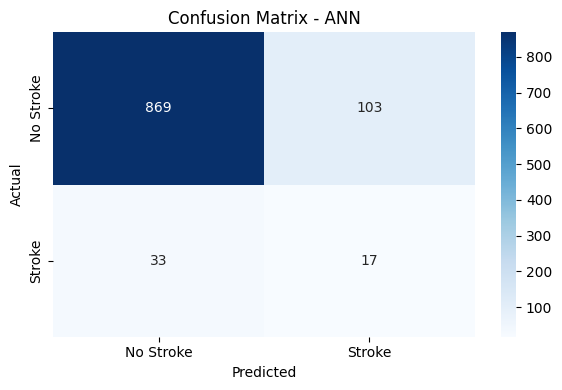

In [11]:
for name in models.keys():

    cm = confusion_matrix(
        y_test,
        predictions[name],
        labels=[0, 1]
    )

    plt.figure(figsize=(6, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['No Stroke', 'Stroke'],
        yticklabels=['No Stroke', 'Stroke']
    )

    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')

    plt.tight_layout()
    plt.show()

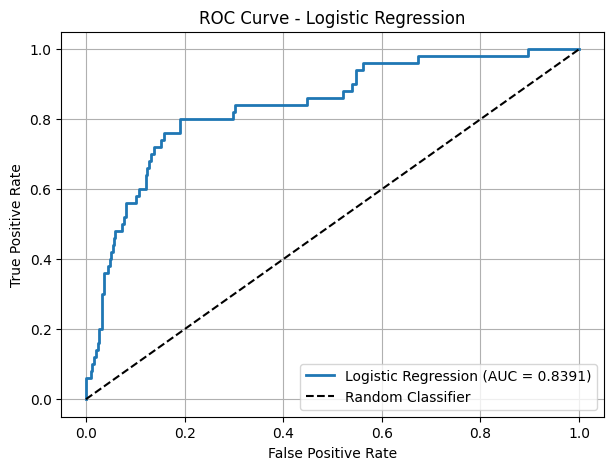

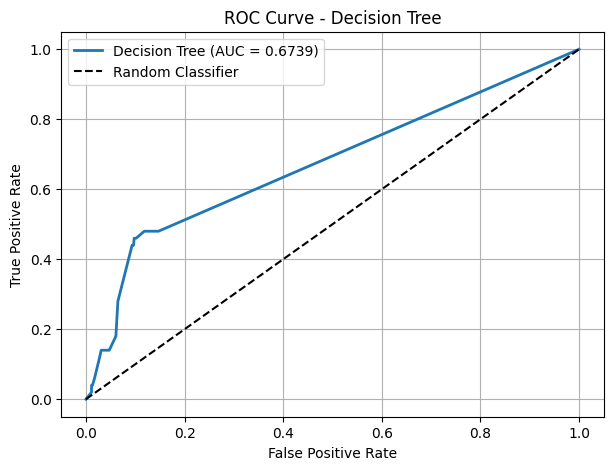

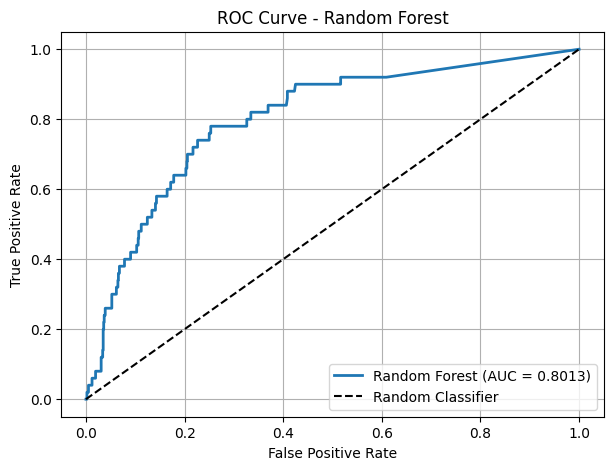

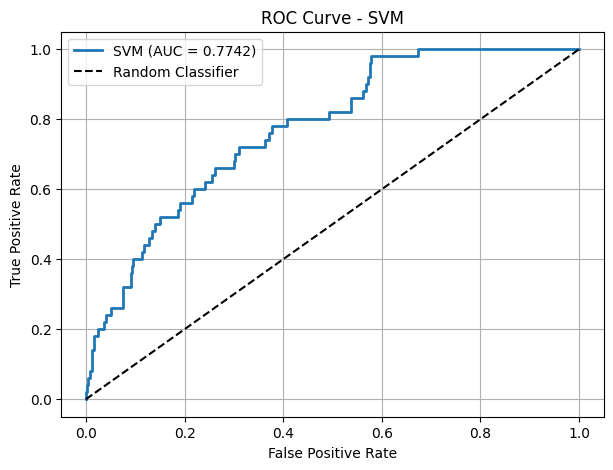

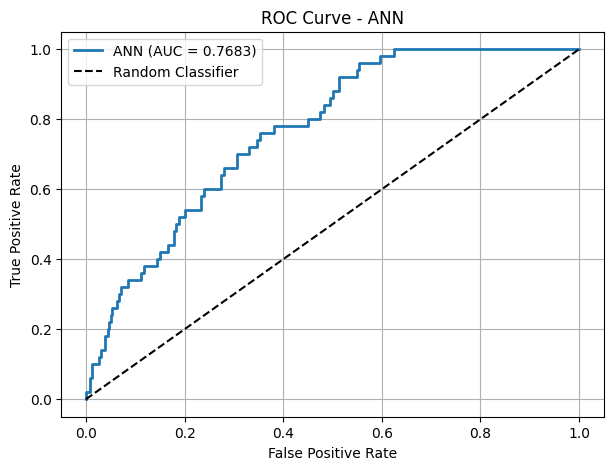

In [12]:
for name in models.keys():

    fpr, tpr, thresholds = roc_curve(
        y_test,
        probabilities[name]
    )

    auc_score = roc_auc_score(
        y_test,
        probabilities[name]
    )

    plt.figure(figsize=(7, 5))

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f'{name} (AUC = {auc_score:.4f})'
    )

    plt.plot(
        [0, 1],
        [0, 1],
        'k--',
        label='Random Classifier'
    )

    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')

    plt.title(f'ROC Curve - {name}')

    plt.legend()
    plt.grid()

    plt.show()

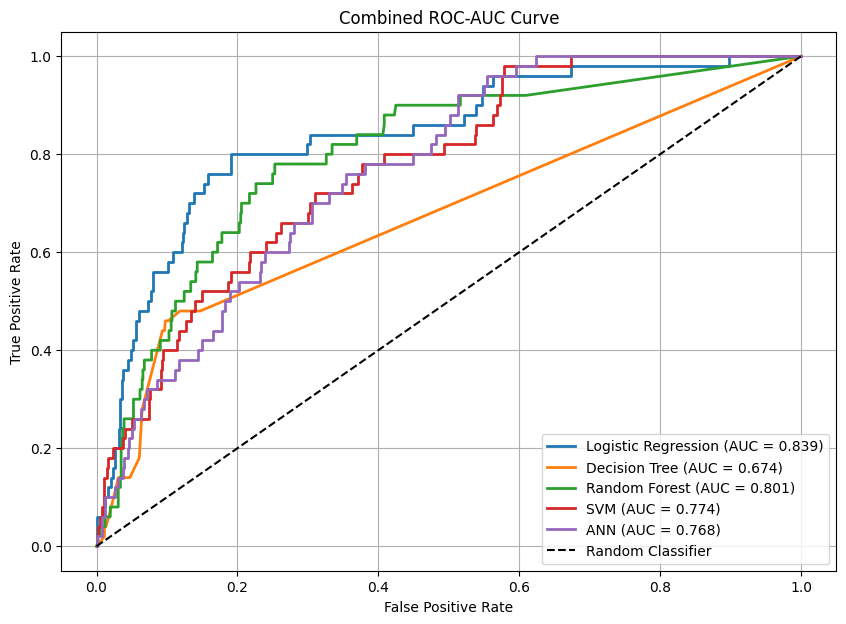

In [13]:
plt.figure(figsize=(10, 7))

for name in models.keys():

    fpr, tpr, thresholds = roc_curve(
        y_test,
        probabilities[name]
    )

    auc_score = roc_auc_score(
        y_test,
        probabilities[name]
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f'{name} (AUC = {auc_score:.3f})'
    )

plt.plot(
    [0, 1],
    [0, 1],
    'k--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.title('Combined ROC-AUC Curve')

plt.legend(loc='lower right')
plt.grid()

plt.show()

In [14]:
results_df['Ranking Score'] = (
    0.40 * results_df['Recall'] +
    0.30 * results_df['F1-Score'] +
    0.30 * results_df['AUC-ROC']
)

results_df = results_df.sort_values(
    by='Ranking Score',
    ascending=False
).reset_index(drop=True)

top3 = results_df.head(3)

print("TOP 3 MODELS FOR STROKE PREDICTION")

display(
    top3.style.format({
        'Accuracy': '{:.4f}',
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F1-Score': '{:.4f}',
        'AUC-ROC': '{:.4f}',
        'Ranking Score': '{:.4f}'
    })
)

TOP 3 MODELS FOR STROKE PREDICTION


,Model,Accuracy,Precision,Recall,F1-Score,AUC-ROC,Ranking Score
0,Logistic Regression,0.7456,0.1379,0.8000,0.2353,0.8391,0.6423
1,SVM,0.7466,0.1144,0.6200,0.1931,0.7742,0.5382
2,Decision Tree,0.8346,0.1437,0.4800,0.2212,0.6739,0.4605


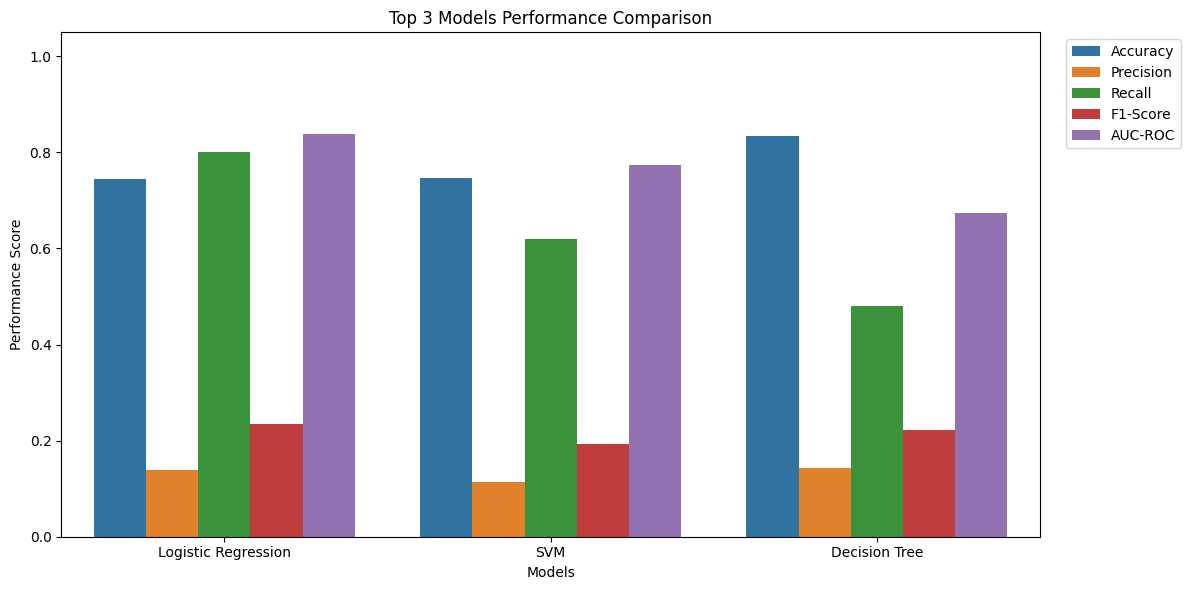

In [15]:
top3_melted = top3.melt(
    id_vars='Model',
    value_vars=[
        'Accuracy',
        'Precision',
        'Recall',
        'F1-Score',
        'AUC-ROC'
    ],
    var_name='Metric',
    value_name='Score'
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top3_melted,
    x='Model',
    y='Score',
    hue='Metric'
)

plt.title('Top 3 Models Performance Comparison')

plt.xlabel('Models')
plt.ylabel('Performance Score')

plt.ylim(0, 1.05)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()

In [16]:
for name in top3['Model']:

    print("\n====================================")
    print("MODEL:", name)
    print("====================================")

    print(
        classification_report(
            y_test,
            predictions[name],
            target_names=['No Stroke', 'Stroke'],
            zero_division=0
        )
    )

    cm = confusion_matrix(
        y_test,
        predictions[name]
    )

    print("Confusion Matrix:")
    print(cm)


MODEL: Logistic Regression
              precision    recall  f1-score   support

   No Stroke       0.99      0.74      0.85       972
      Stroke       0.14      0.80      0.24        50

    accuracy                           0.75      1022
   macro avg       0.56      0.77      0.54      1022
weighted avg       0.94      0.75      0.82      1022

Confusion Matrix:
[[722 250]
 [ 10  40]]

MODEL: SVM
              precision    recall  f1-score   support

   No Stroke       0.97      0.75      0.85       972
      Stroke       0.11      0.62      0.19        50

    accuracy                           0.75      1022
   macro avg       0.54      0.69      0.52      1022
weighted avg       0.93      0.75      0.82      1022

Confusion Matrix:
[[732 240]
 [ 19  31]]

MODEL: Decision Tree
              precision    recall  f1-score   support

   No Stroke       0.97      0.85      0.91       972
      Stroke       0.14      0.48      0.22        50

    accuracy                          

In [17]:
best_model = top3.iloc[0]

best_recall = results_df.loc[
    results_df['Recall'].idxmax()
]

best_auc = results_df.loc[
    results_df['AUC-ROC'].idxmax()
]

print("\n========== FINAL STROKE ANALYSIS ==========")

print("\nBest Overall Model:", best_model['Model'])

print("Ranking Score:", round(
    best_model['Ranking Score'], 4
))

print("\nBest Model for Stroke Detection:",
      best_recall['Model'])

print("Highest Recall:",
      round(best_recall['Recall'], 4))

print("\nBest Model Based on AUC:",
      best_auc['Model'])

print("Highest AUC:",
      round(best_auc['AUC-ROC'], 4))

print("\nTop 3 Models:")

for i, row in top3.iterrows():
    print(f"{i+1}. {row['Model']}")

print("\nConclusion:")
print(
    f"{best_model['Model']} achieved the highest "
    "weighted ranking score among the five models."
)


========== FINAL STROKE ANALYSIS ==========

Best Overall Model: Logistic Regression
Ranking Score: 0.6423

Best Model for Stroke Detection: Logistic Regression
Highest Recall: 0.8

Best Model Based on AUC: Logistic Regression
Highest AUC: 0.8391

Top 3 Models:
1. Logistic Regression
2. SVM
3. Decision Tree

Conclusion:
Logistic Regression achieved the highest weighted ranking score among the five models.


In [18]:
# Save complete performance comparison
results_df.to_csv(
    'Stroke_Model_Results.csv',
    index=False
)

# Save top 3 models
top3.to_csv(
    'Stroke_Top_3_Models.csv',
    index=False
)

# Download files
files.download('Stroke_Model_Results.csv')

files.download('Stroke_Top_3_Models.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>